# LAB 08 — Tokenization, attention mask và MLM
Tokenizer của pretrained model **`distilbert-base-uncased`** (WordPiece, chữ thường, vocabulary 30,522). Notebook này chạy trên CPU.

In [1]:
import sys, math, warnings
sys.path.insert(0, "../lab04")
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel, AutoModelForMaskedLM
import preprocessing as pp
warnings.filterwarnings("ignore"); torch.manual_seed(2026)
MODEL = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(MODEL)
print(type(tok).__name__, "| vocabulary:", len(tok), "| max length:", tok.model_max_length)

C:\Users\dinhb\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


BertTokenizer | vocabulary: 30522 | max length: 512


## 12.1 Tokenization — `tokens.keys()`, `input_ids`, `attention_mask` (Calculation Exercise 2)

In [2]:
tokens = tok(["The cats are playing.", "The cat eats fish"], padding=True, truncation=True, return_tensors="pt")
print("keys:", list(tokens.keys()))
for i in range(2):
    display(pd.DataFrame({"token": tok.convert_ids_to_tokens(tokens["input_ids"][i]), "input_id": tokens["input_ids"][i].tolist(),
                          "attention_mask": tokens["attention_mask"][i].tolist()}).T)
print("special tokens:", dict(zip(tok.all_special_tokens, tok.all_special_ids)))
s = "The cats are playing."; ids = tok(s)["input_ids"]; pieces = tok.tokenize(s)
print(f"words = {len(s.split())} | tokens (không special) = {len(pieces)} | subword '##' = {sum(p.startswith('##') for p in pieces)} | input_ids = {len(ids)}")

keys: ['input_ids', 'token_type_ids', 'attention_mask']


,0,1,2,3,4,5,6
token,[CLS],the,cats,are,playing,.,[SEP]
input_id,101,1996,8870,2024,2652,1012,102
attention_mask,1,1,1,1,1,1,1


,0,1,2,3,4,5,6
token,[CLS],the,cat,eats,fish,[SEP],[PAD]
input_id,101,1996,4937,20323,3869,102,0
attention_mask,1,1,1,1,1,1,0


special tokens: {'[UNK]': 100, '[SEP]': 102, '[PAD]': 0, '[CLS]': 101, '[MASK]': 103}
words = 4 | tokens (không special) = 5 | subword '##' = 0 | input_ids = 7


- **`input_ids`**: chỉ số của từng token trong vocabulary; đây là input của embedding layer. Tokenizer tự thêm **[CLS]** (101) ở đầu và **[SEP]** (102) ở cuối.
- **`attention_mask`**: 1 = token thật, 0 = [PAD] (id 0) thêm vào để các câu trong batch cùng độ dài. Câu thứ hai ngắn hơn nên có một vị trí mask 0.
- DistilBERT không dùng `token_type_ids` (BERT gốc có, để phân biệt sentence A / B).

## Subword tokens và special tokens

In [3]:
words = ["unbelievable", "unbelievably", "tokenization", "playing", "gigolo", "macliammoir", "rajinikanth", "covid", "lol", "omg", "awesomeee", "5/10"]
display(pd.DataFrame({"word": words, "tokens": [" ".join(tok.tokenize(w)) for w in words], "số token": [len(tok.tokenize(w)) for w in words]}).set_index("word"))
pair = tok("this movie is great", "the acting was bad"); print("câu đôi:", " ".join(tok.convert_ids_to_tokens(pair["input_ids"])))

,tokens,số token
word,,
unbelievable,unbelievable,1
unbelievably,un ##bel ##ie ##va ##bly,5
tokenization,token ##ization,2
playing,playing,1
gigolo,gig ##olo,2
macliammoir,mac ##lia ##mm ##oir,4
rajinikanth,raj ##ini ##kan ##th,4
covid,co ##vid,2
lol,lo ##l,2


câu đôi: [CLS] this movie is great [SEP] the acting was bad [SEP]


Từ phổ biến giữ nguyên một token ("unbelievable", "playing"), nhưng "unbelievably" thành 5 mảnh (un ##bel ##ie ##va ##bly), không theo ranh giới hình vị như un + believe + able; từ hiếm/tên riêng/từ viết sai bị cắt thành nhiều mảnh "##" thay vì thành [UNK]. Vì vậy subword tokenizer **giải quyết vấn đề out-of-vocabulary** của LAB 04–07 (ở đó từ ngoài 20,000 từ thành `<unk>`), đổi lại sequence dài hơn.

## Words vs tokens trên IMDb (ảnh hưởng tới max_length)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (544 > 512). Running this sequence through the model will result in indexing errors


trung vị: 174 words → 226 tokens (tỉ lệ token/word ≈ 1.28)
mảnh '##' chiếm 5.3% token | [UNK] chiếm 0.000%


,pct_reviews_fully_kept,pct_tokens_kept
max_length,,
64,2.6,21.5
128,12.5,41.6
256,58.3,68.8
512,87.4,89.4


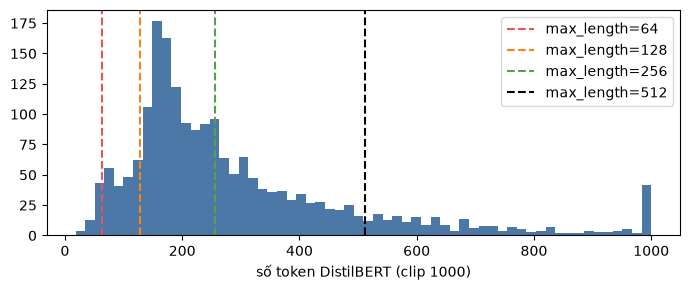

In [4]:
data = pp.prepare(pp.load_imdb()); train, val, test = pp.split(data)
sample = test.text.sample(2000, random_state=2026).tolist()
n_words = np.array([len(t.split()) for t in sample]); n_tok = np.array([len(tok(t)["input_ids"]) for t in sample])
pieces = [p for t in sample[:500] for p in tok.tokenize(t)]
print(f"trung vị: {np.median(n_words):.0f} words → {np.median(n_tok):.0f} tokens (tỉ lệ token/word ≈ {np.median(n_tok/n_words):.2f})")
print(f"mảnh '##' chiếm {np.mean([p.startswith('##') for p in pieces]):.1%} token | [UNK] chiếm {np.mean([p == '[UNK]' for p in pieces]):.3%}")
rows = [dict(max_length=L, pct_reviews_fully_kept=round((n_tok <= L).mean()*100, 1), pct_tokens_kept=round(np.minimum(n_tok, L).sum()/n_tok.sum()*100, 1)) for L in (64, 128, 256, 512)]
display(pd.DataFrame(rows).set_index("max_length"))
plt.figure(figsize=(7, 3)); plt.hist(np.clip(n_tok, 0, 1000), bins=60, color="#4c78a8")
for L, c in ((64, "#e45756"), (128, "#f58518"), (256, "#54a24b"), (512, "black")): plt.axvline(L, color=c, ls="--", label=f"max_length={L}")
plt.xlabel("số token DistilBERT (clip 1000)"); plt.legend(); plt.tight_layout(); plt.show()

Review IMDb trung vị 174 words thành 226 token (≈ 1.28 token/word, mảnh "##" chiếm 5.3%, gần như không có [UNK]). Với max_length 256 chỉ 58% review được giữ nguyên vẹn (69% token); 512 (giới hạn của DistilBERT) giữ 87%. Subword làm sequence dài hơn word nên truncation nặng hơn so với LAB 07.

## 7. Attention mask có tác dụng thật không?
Cùng câu "the cat eats fish", so sánh vector [CLS] khi (a) không pad, (b) pad thêm 3 [PAD] **có** attention mask đúng, (c) pad thêm 3 [PAD] nhưng mask toàn 1.

In [5]:
enc = AutoModel.from_pretrained(MODEL).eval()
a = tok("the cat eats fish", return_tensors="pt"); b = tok("the cat eats fish", padding="max_length", max_length=a["input_ids"].shape[1] + 3, return_tensors="pt")
with torch.no_grad():
    h_a = enc(**a).last_hidden_state[0, 0]; h_b = enc(**b).last_hidden_state[0, 0]
    h_c = enc(input_ids=b["input_ids"], attention_mask=torch.ones_like(b["attention_mask"])).last_hidden_state[0, 0]
print("input_ids (b):", b["input_ids"].tolist(), "| attention_mask:", b["attention_mask"].tolist())
print(f"‖CLS(a) − CLS(b, mask đúng)‖ = {(h_a - h_b).norm():.6f}")
print(f"‖CLS(a) − CLS(c, mask toàn 1)‖ = {(h_a - h_c).norm():.4f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 3572.75it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


input_ids (b): [[101, 1996, 4937, 20323, 3869, 102, 0, 0, 0]] | attention_mask: [[1, 1, 1, 1, 1, 1, 0, 0, 0]]
‖CLS(a) − CLS(b, mask đúng)‖ = 0.000004
‖CLS(a) − CLS(c, mask toàn 1)‖ = 3.2359


Với mask đúng, thêm [PAD] không làm đổi representation (chỉ sai số số học); nếu mask toàn 1 thì [PAD] được attend như nội dung thật và vector [CLS] thay đổi. Attention mask giữ cho padding không tham gia như nội dung của sequence.

## 8–9. Masked Language Modeling với model pretrained thật
"The cat [MASK] fish." → xác suất top-8 token tại vị trí [MASK] và loss L = −log P(token đúng).

In [6]:
mlm = AutoModelForMaskedLM.from_pretrained(MODEL).eval()
def mlm_top(text, k=8):
    x = tok(text, return_tensors="pt"); pos = (x["input_ids"][0] == tok.mask_token_id).nonzero()[0, 0]
    with torch.no_grad(): p = torch.softmax(mlm(**x).logits[0, pos], -1)
    top = torch.topk(p, k); return p, [(tok.convert_ids_to_tokens(int(i)), round(float(v), 4)) for v, i in zip(top.values, top.indices)]
p, top = mlm_top("The cat [MASK] fish."); print("top-8:", top)
for w in ("eats", "catches", "likes", "dog"):
    pw = float(p[tok.convert_tokens_to_ids(w)]); print(f"P({w}) = {pw:.4f} → L = −ln P = {-math.log(pw):.3f}")
for s in ("This movie was absolutely [MASK].", "The acting was [MASK], I want my money back.", "Paris is the capital of [MASK]."):
    print(s, "→", mlm_top(s, 5)[1])

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 3749.79it/s]

top-8: [('eats', 0.3505), ('##tail', 0.0734), ('attracts', 0.0649), ('ate', 0.0449), ('hunts', 0.0312), ('loves', 0.0275), ('eat', 0.0153), ('hates', 0.0142)]
P(eats) = 0.3505 → L = −ln P = 1.048
P(catches) = 0.0096 → L = −ln P = 4.645
P(likes) = 0.0045 → L = −ln P = 5.413
P(dog) = 0.0002 → L = −ln P = 8.594
This movie was absolutely [MASK]. → [('fantastic', 0.1392), ('fabulous', 0.0807), ('hilarious', 0.0479), ('incredible', 0.0295), ('terrible', 0.0257)]
The acting was [MASK], I want my money back. → [('gone', 0.0232), ('done', 0.0217), ('ridiculous', 0.013), ('bullshit', 0.0126), ('awful', 0.0122)]
Paris is the capital of [MASK]. → [('france', 0.486), ('martinique', 0.0967), ('algeria', 0.0403), ('haiti', 0.028), ('brittany', 0.0236)]


Model pretrained bằng MLM đặt **"eats"** lên đầu (P = 0.35, loss 1.048) cho "The cat [MASK] fish.", các lựa chọn tiếp theo cũng là động từ hợp nghĩa (attracts, ate, hunts, loves), còn "dog" gần như 0 (loss 8.59). Với câu đánh giá, model điền từ khen ("fantastic", "fabulous") hoặc chê ("ridiculous", "awful" sau "I want my money back"), và "france" cho "Paris is the capital of [MASK]". Đây là kiến thức ngôn ngữ và kiến thức thế giới có sẵn **trước khi** thấy dữ liệu IMDb có nhãn, là cơ sở để fine-tuning hiệu quả với ít dữ liệu. Lưu ý loss thật (1.048) cao hơn ví dụ tính tay (0.357) vì model chia xác suất cho nhiều động từ hợp lý.